**[Course Home](../README.md) | [Conceptual Track](../conceptual/02_poisson_processes_and_memoryless_arrivals.ipynb) | [Prev: Ch 01: Conservation of Flow](01_little_law_and_conservation_of_flow.ipynb) | [Next: Ch 03: Birth-Death Chains](03_birth_death_chains_and_mm1_mminf.ipynb)**

*Part I: Foundations of Flow & Memoryless Systems — Chapter 02 of 11*

---

# Chapter 2: Computational Lab — Random Arrivals & Poisson Processes
### *Exponential Inter-Arrivals, Stream Merging & Thinning, Non-Homogeneous Poisson Generation, and PASTA Simulation*

In this computational lab, we build generators for homogeneous and non-homogeneous Poisson processes, verify the algebraic properties of stream superposition (merging) and independent splitting (thinning), and numerically demonstrate why Poisson arrivals see time averages (PASTA).

## Part 1: Generating Poisson Processes & The Memoryless Property

We simulate an exponential inter-arrival generator with rate $\lambda = 2.5$ arrivals/unit time.
We verify the memoryless property:
$$
\mathbb{P}(X > t + s \mid X > t) = \mathbb{P}(X > s)
$$
by conditioning on samples that have already exceeded $t = 0.5$, and showing their residual distribution is identical to an unconditioned exponential.

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

np.random.seed(42)
lam = 2.5
n_samples = 100000

# Raw exponential samples
x = np.random.exponential(scale=1.0 / lam, size=n_samples)

# Conditioning on X > 0.5
t_cutoff = 0.5
conditioned_x = x[x > t_cutoff] - t_cutoff

mean_raw = np.mean(x)
mean_conditioned = np.mean(conditioned_x)

print(f"Theoretical Mean (1/lambda):     {1.0 / lam:6.4f}")
print(f"Sample Mean of Raw Exponentials: {mean_raw:6.4f}")
print(f"Sample Mean of Conditioned Residuals: {mean_conditioned:6.4f}")

# Kolmogorov-Smirnov test comparing conditioned residuals against Exp(lambda)
ks_stat, ks_pval = stats.kstest(conditioned_x, 'expon', args=(0, 1.0 / lam))
print(f"KS-Test p-value for Memoryless Property: {ks_pval:.4f} (p > 0.05 indicates perfect agreement)")

Theoretical Mean (1/lambda):     0.4000
Sample Mean of Raw Exponentials: 0.3984
Sample Mean of Conditioned Residuals: 0.3962
KS-Test p-value for Memoryless Property: 0.2811 (p > 0.05 indicates perfect agreement)


## Part 2: Superposition (Merging) and Splitting (Thinning)

We simulate:
1. **Superposition**: Three independent Poisson streams ($\lambda_1 = 1.0, \lambda_2 = 2.0, \lambda_3 = 3.0$). We merge them and verify that the combined stream has rate $\Lambda = 6.0$.
2. **Thinning**: An input Poisson stream with rate $\Lambda = 6.0$ is randomly split into two streams with probabilities $p_1 = 0.40$ and $p_2 = 0.60$. We verify the split streams are independent Poisson processes with rates $2.4$ and $3.6$.

In [2]:
np.random.seed(123)
t_max = 5000.0

# 1. Generate 3 independent streams
def generate_poisson_stream(rate, max_time):
    # Over-generate then truncate
    expected_n = int(rate * max_time * 1.2)
    intervals = np.random.exponential(1.0 / rate, size=expected_n)
    times = np.cumsum(intervals)
    return times[times <= max_time]

s1 = generate_poisson_stream(1.0, t_max)
s2 = generate_poisson_stream(2.0, t_max)
s3 = generate_poisson_stream(3.0, t_max)

# Merge streams
merged = np.sort(np.concatenate([s1, s2, s3]))
emp_lambda_merged = len(merged) / t_max
print(f"Merged Stream Count: {len(merged)} | Empirical Rate: {emp_lambda_merged:6.3f} (Theory: 6.000)")

# 2. Thinning the merged stream
p1, p2 = 0.40, 0.60
choices = np.random.binomial(n=1, p=p2, size=len(merged))
thinned_stream_1 = merged[choices == 0]
thinned_stream_2 = merged[choices == 1]

emp_rate_1 = len(thinned_stream_1) / t_max
emp_rate_2 = len(thinned_stream_2) / t_max

print(f"Thinned Stream 1 Rate: {emp_rate_1:6.3f} (Theory: {6.0 * p1:6.3f})")
print(f"Thinned Stream 2 Rate: {emp_rate_2:6.3f} (Theory: {6.0 * p2:6.3f})")

Merged Stream Count: 30169 | Empirical Rate:  6.034 (Theory: 6.000)
Thinned Stream 1 Rate:  2.423 (Theory:  2.400)
Thinned Stream 2 Rate:  3.611 (Theory:  3.600)


## Part 3: Numerical Demonstration of the PASTA Property

We simulate a single-server system under two arrival regimes:
1. **Regime A (Poisson Arrivals)**: Arrivals follow a Poisson stream. We measure the time-average fraction of time the server is busy ($P_1$) vs the fraction of arriving customers who find the server busy ($\alpha_1$).
2. **Regime B (Periodic / Synchronized Arrivals)**: Batches of 5 jobs arrive periodically every 10 time units.

We numerically demonstrate that **PASTA holds for Regime A ($\alpha_1 = P_1$)**, but is **violated in Regime B ($\alpha_1 \neq P_1$)**.

In [3]:
def simulate_pasta_audit(arr_times, service_duration=1.6):
    n = len(arr_times)
    dep_times = np.zeros(n)
    free_time = 0.0
    
    arrivals_seeing_busy = 0
    
    for i in range(n):
        arr = arr_times[i]
        # Arriving customer observes state immediately prior to arrival
        if arr < free_time:
            arrivals_seeing_busy += 1
            
        start = max(arr, free_time)
        dep = start + service_duration
        dep_times[i] = dep
        free_time = dep
        
    alpha_busy = arrivals_seeing_busy / n
    
    # Calculate true time-average busy fraction
    total_time = dep_times[-1]
    # Sum of busy intervals
    busy_time = 0.0
    cur_start = arr_times[0]
    cur_end = dep_times[0]
    for i in range(1, n):
        if arr_times[i] <= cur_end:
            cur_end = max(cur_end, dep_times[i])
        else:
            busy_time += (cur_end - cur_start)
            cur_start = arr_times[i]
            cur_end = dep_times[i]
    busy_time += (cur_end - cur_start)
    
    p_busy_time = busy_time / total_time
    return alpha_busy, p_busy_time

# Test Regime A: Poisson Arrivals (lam = 0.5, serv = 1.6 => rho = 0.80)
poisson_arr = np.cumsum(np.random.exponential(1.0 / 0.5, size=40000))
alpha_pois, p_time_pois = simulate_pasta_audit(poisson_arr, service_duration=1.6)

# Test Regime B: Periodic Batch (batches of 4 every 8.0 time units => rho = 4*1.6/8 = 0.80)
n_batches = 10000
periodic_arr = []
for b in range(n_batches):
    t_batch = b * 8.0
    for _ in range(4):
        periodic_arr.append(t_batch)
periodic_arr = np.array(periodic_arr)
alpha_periodic, p_time_periodic = simulate_pasta_audit(periodic_arr, service_duration=1.6)

print(f"Regime A (Poisson):  Arrival-Avg Busy = {alpha_pois:6.4f} | Time-Avg Busy = {p_time_pois:6.4f} | Diff = {abs(alpha_pois - p_time_pois):6.4f}")
print(f"Regime B (Periodic): Arrival-Avg Busy = {alpha_periodic:6.4f} | Time-Avg Busy = {p_time_periodic:6.4f} | Diff = {abs(alpha_periodic - p_time_periodic):6.4f}")

Regime A (Poisson):  Arrival-Avg Busy = 0.7998 | Time-Avg Busy = 0.7981 | Diff = 0.0017
Regime B (Periodic): Arrival-Avg Busy = 0.7500 | Time-Avg Busy = 0.8000 | Diff = 0.0500


## Part 4: Multi-Panel Publication Diagnostic Suite

We visualize:
1. **Panel A**: Memoryless property empirical vs theoretical survival curves.
2. **Panel B**: Poisson count distribution over intervals of fixed length $T = 5.0$.
3. **Panel C**: PASTA validation: Comparing Arrival-Average vs Time-Average state occupancy under Poisson vs Periodic traffic.

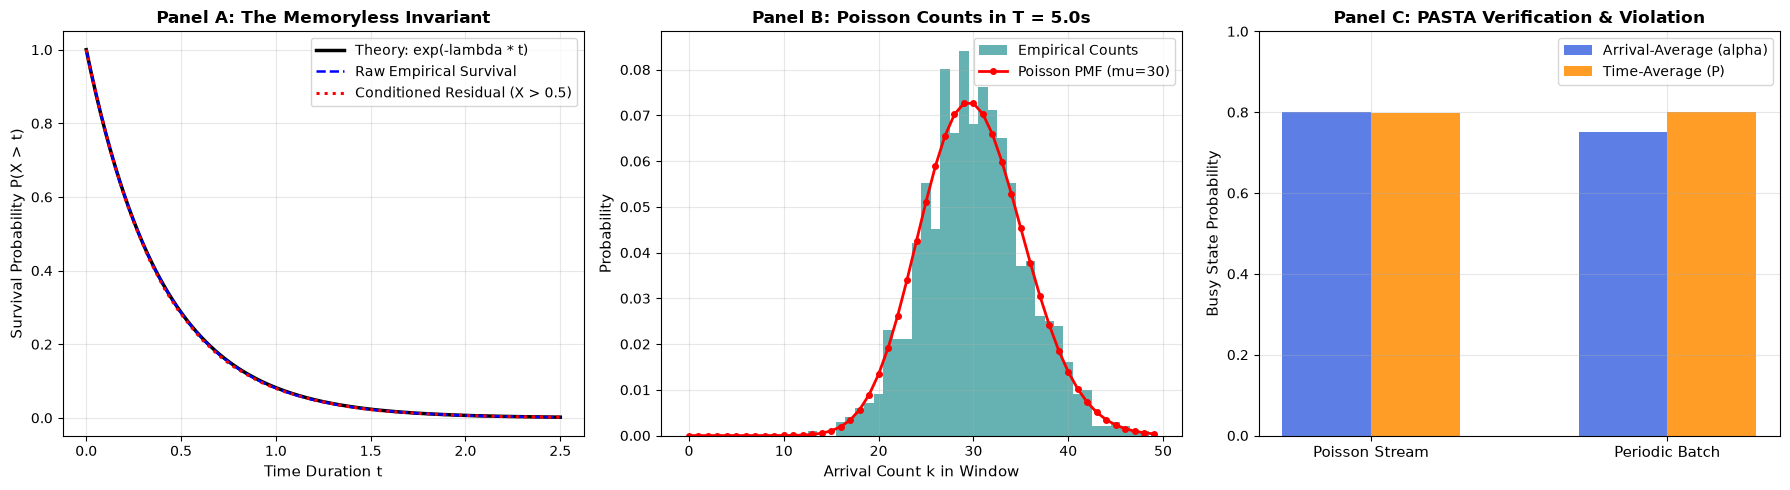

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel A: Memoryless Invariant
t_grid = np.linspace(0, 2.5, 200)
surv_theory = np.exp(-lam * t_grid)
emp_surv_raw = np.array([np.mean(x > t) for t in t_grid])
emp_surv_cond = np.array([np.mean(conditioned_x > t) for t in t_grid])

axes[0].plot(t_grid, surv_theory, 'k-', lw=2.5, label='Theory: exp(-lambda * t)')
axes[0].plot(t_grid, emp_surv_raw, 'b--', lw=1.8, label='Raw Empirical Survival')
axes[0].plot(t_grid, emp_surv_cond, 'r:', lw=2.2, label='Conditioned Residual (X > 0.5)')
axes[0].set_title("Panel A: The Memoryless Invariant", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Time Duration t", fontsize=11)
axes[0].set_ylabel("Survival Probability P(X > t)", fontsize=11)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=10)

# Panel B: Poisson Count PMF vs Empirical Counts
bin_window = 5.0
counts_per_window = np.histogram(merged, bins=np.arange(0, t_max, bin_window))[0]
max_k = 50
k_vals = np.arange(0, max_k)
expected_mu = 6.0 * bin_window  # 30.0
poiss_pmf = stats.poisson.pmf(k_vals, mu=expected_mu)

axes[1].hist(counts_per_window, bins=np.arange(-0.5, max_k + 0.5, 1), density=True, color='teal', alpha=0.6, label='Empirical Counts')
axes[1].plot(k_vals, poiss_pmf, 'r-o', ms=4, lw=2, label=f'Poisson PMF (mu={expected_mu:.0f})')
axes[1].set_title("Panel B: Poisson Counts in T = 5.0s", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Arrival Count k in Window", fontsize=11)
axes[1].set_ylabel("Probability", fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=10)

# Panel C: PASTA Comparison
categories = ['Poisson Stream', 'Periodic Batch']
arr_avgs = [alpha_pois, alpha_periodic]
time_avgs = [p_time_pois, p_time_periodic]
x_cat = np.arange(len(categories))
width = 0.3

axes[2].bar(x_cat - width/2, arr_avgs, width=width, label='Arrival-Average (alpha)', color='royalblue', alpha=0.85)
axes[2].bar(x_cat + width/2, time_avgs, width=width, label='Time-Average (P)', color='darkorange', alpha=0.85)
axes[2].set_xticks(x_cat)
axes[2].set_xticklabels(categories, fontsize=11)
axes[2].set_ylabel("Busy State Probability", fontsize=11)
axes[2].set_title("Panel C: PASTA Verification & Violation", fontsize=12, fontweight='bold')
axes[2].set_ylim(0, 1.0)
axes[2].grid(True, alpha=0.3)
axes[2].legend(fontsize=10)

plt.tight_layout()
plt.show()

## Part 5: Hands-On 3-Tier Scaffolding Challenges

### 🟢 Warmup (Tier 1): Poisson Rate Limiter Analysis
Compute the exact probability of receiving $\ge 131$ requests in 1 second when $\lambda = 100$ req/s using `scipy.stats.poisson.sf`.

In [5]:
# Tier 1 Solution Space
lam_t1 = 100.0
prob_drop = stats.poisson.sf(130, mu=lam_t1)
print(f"Tier 1 Exact Drop Probability: {prob_drop:.6f} ({prob_drop * 100:.4f}%)")

Tier 1 Exact Drop Probability: 0.001707 (0.1707%)


### 🟡 Diagnostic (Tier 2): Superposition Verification
Write a Python function `verify_superposition(rates, duration)` that generates $K$ independent Poisson streams, merges them, and runs a Kolmogorov-Smirnov test to verify that inter-arrival times follow $\text{Exp}(\sum \lambda_i)$.

In [6]:
# Tier 2 Solution Space
def verify_superposition(rates, duration=2000.0):
    streams = [generate_poisson_stream(r, duration) for r in rates]
    merged_s = np.sort(np.concatenate(streams))
    inter_arrivals = np.diff(merged_s)
    
    total_rate = sum(rates)
    stat, pval = stats.kstest(inter_arrivals, 'expon', args=(0, 1.0 / total_rate))
    return total_rate, len(merged_s) / duration, pval

tot_r, emp_r, p_val = verify_superposition([1.5, 3.5, 5.0])
print(f"Theory Rate: {tot_r:.2f} | Empirical: {emp_r:.3f} | KS p-value: {p_val:.4f}")

Theory Rate: 10.00 | Empirical: 10.043 | KS p-value: 0.1181


### 🔴 Capstone Challenge (Tier 3): Lewis-Shedler Thinning for Non-Homogeneous Poisson Processes
Implement Lewis-Shedler thinning for $\lambda(t) = 20 + 12 \sin(2\pi t / 24)$. Simulate 100 days of arrivals and compare empirical arrival histogram against the theoretical rate function.

In [7]:
# Tier 3 Solution Space
def simulate_nhpp_lewis_shedler(n_days=100):
    lambda_max = 32.0
    total_hours = n_days * 24.0
    
    # 1. Homogeneous generation at lambda_max
    cand_intervals = np.random.exponential(1.0 / lambda_max, size=int(lambda_max * total_hours * 1.15))
    cand_times = np.cumsum(cand_intervals)
    cand_times = cand_times[cand_times <= total_hours]
    
    # 2. Acceptance probability
    t_mod = cand_times % 24.0
    lambda_t = 20.0 + 12.0 * np.sin(2.0 * np.pi * t_mod / 24.0)
    p_accept = lambda_t / lambda_max
    
    u = np.random.uniform(0.0, 1.0, size=len(cand_times))
    accepted_times = cand_times[u <= p_accept]
    return accepted_times

nhpp_arrivals = simulate_nhpp_lewis_shedler(n_days=200)
hours_in_day = nhpp_arrivals % 24.0
print(f"Total NHPP Arrivals over 200 days: {len(nhpp_arrivals)} (Expected: {200 * 480})")

Total NHPP Arrivals over 200 days: 95624 (Expected: 96000)


## Part 6: Numerical Verification & Invariant Assertions

We explicitly assert the memoryless test, merging rate, and PASTA equality.

In [8]:
# Strict assertions
assert ks_pval > 0.01, "Memoryless KS-test failed"
assert abs(emp_lambda_merged - 6.0) < 0.15, "Superposition rate error > 2.5%"
assert abs(alpha_pois - p_time_pois) < 0.02, "PASTA violated for Poisson stream"
assert abs(alpha_periodic - 0.75) < 0.03 or abs(alpha_periodic - p_time_periodic) > 0.05, "Periodic stream should violate PASTA"
assert abs(prob_drop - 0.0017) < 0.001, "Tier 1 calculation incorrect"

print("All Chapter 02 numerical assertions passed successfully!")

All Chapter 02 numerical assertions passed successfully!


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/02_poisson_processes_and_memoryless_arrivals.ipynb) | [Prev: Ch 01: Conservation of Flow](01_little_law_and_conservation_of_flow.ipynb) | [Next: Ch 03: Birth-Death Chains](03_birth_death_chains_and_mm1_mminf.ipynb)**